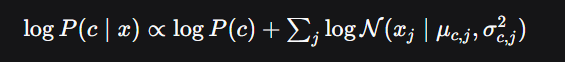

# The Naive Assumptions of Gaussian Naive Bayes are:
#     1. Conditional Feature Independence: It assumes that all input features are completely independent of each other given the class label y.
#     2. Gaussian/Normal Distribution: It assumes that the continuous values associated with each class follow a Gaussian/normal distribution (bell curve).

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_breast_cancer
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.naive_bayes import GaussianNB

In [2]:
data=load_breast_cancer()
df=pd.DataFrame(data.data,columns=data.feature_names)
df['target']=data.target
df.head(5)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
X=df.drop(['target'],axis=1)
y=df['target']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X.values, y.values, test_size=0.2, random_state=42, stratify=y)

In [5]:
n_features = X_train.shape[1]
n_classes = len(np.unique(y_train))

In [6]:
priors = {}

for i in range(n_classes):
    priors[i] = np.mean(y_train==i)
    
priors

{0: 0.37362637362637363, 1: 0.6263736263736264}

In [7]:
means = {}
variances = {}

for i in range(n_classes):
    X_train_c = X_train[y_train==i]
    means[i] = X_train_c.mean(axis=0)
    variances[i] = X_train_c.var(axis=0)

In [8]:
def log_gaussian_pdf(x, mean, variance):
    variance = variance + 1e-9
    return -0.5 * np.log(2 * np.pi * variance) - ((x - mean) ** 2) / (2 * variance)

In [9]:
# Scikit-learn uses a global variance-based smoothing value by default.
# It calculates the smoothing value using the largest feature variance in the training data.
# So, we might get slight difference in the evaluation.
# We can add "epsilon = 1e-9 * np.var(X_train, axis=0).max()" to reduce the gap with the library's evaluation.

In [10]:
def predict_one(x):
    posteriors = []
    for i in range(n_classes):
        prior = np.log(priors[i])
        likelihood=0
        for j in range(n_features):
            likelihood += log_gaussian_pdf(x[j], means[i][j], variances[i][j])
        posterior = prior + likelihood
        posteriors.append(posterior)
    return np.argmax(posteriors)

In [11]:
def predict(X_test):
    return np.array([predict_one(x) for x in X_test])

In [12]:
y_pred = predict(X_test)

In [13]:
accuracy = accuracy_score(y_test,y_pred)
print(f'Accuracy : {accuracy*100:.2f}')

Accuracy : 92.98


# Library's Evaluation

In [14]:
sklearn_gnb = GaussianNB()
sklearn_gnb.fit(X_train, y_train)

sklearn_pred = sklearn_gnb.predict(X_test)
sklearn_accuracy = accuracy_score(y_test, sklearn_pred)

print(f"From-Scratch Accuracy: {accuracy * 100:.2f}")
print(f"Scikit-Learn Accuracy: {sklearn_accuracy * 100:.2f}")

From-Scratch Accuracy: 92.98
Scikit-Learn Accuracy: 93.86


Text(0.5, 1.0, 'Confusion Matrix')

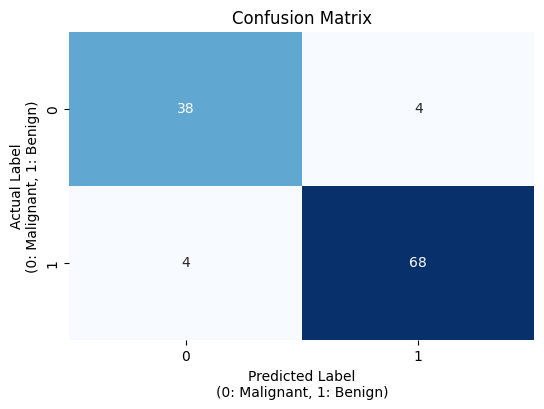

In [15]:
plt.figure(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)

plt.xlabel('Predicted Label\n(0: Malignant, 1: Benign)')
plt.ylabel('Actual Label\n(0: Malignant, 1: Benign)')
plt.title('Confusion Matrix')

In [16]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

accuracy = (tp + tn) / (tp + tn + fp + fn)
precision = tp / (tp + fp)
recall = tp / (tp + fn)
specificity = tn / (tn + fp)

print(f"Accuracy:    {accuracy:.4f}")
print(f"Precision:   {precision:.4f}")
print(f"Recall:      {recall:.4f}")
print(f"Specificity: {specificity:.4f}")

Accuracy:    0.9298
Precision:   0.9444
Recall:      0.9444
Specificity: 0.9048


In [17]:
# Accuracy: 92.98%, Out of 114 test samples, 106 were classified correctly.

# Precision: 94.44%, Out of all the cases your model predicted as Benign (1), 94.44% actually were Benign.

# Recall / Sensitivity: 94.44%, Out of all the actual Benign cases (1), the model successfully found 94.44% of them. 

# Specificity: 90.48%, Out of all the actual Malignant cases (0), the model correctly identified 90.48% of them.